### 10_ElasticNet_Base_MLU

Cible : TousAge_allergie_urgences, le taux de passages aux urgences pour allergie, tous âges, par semaine et par département **de la semaine suivante**..


**Split chronologique:** 

2021–2022 : train -  apprentissage du modèle et des prétraitements.
2023 : valid - comparaison des premiers essais, choix des variables et réglages.
2024 : test - évaluation finale, après avoir arrêté les choix.

0. Moyenne globale de toutes semaines et tout departements confondus (by Mathilde)

1. Model de persistance (2021-2022 train /2023: valid/ 2024 test:)
prévoir le même taux que le dernier connu.

//et pas à expliquer le taux d'une semaine avec les données de la meme semaine, car cela repondrai à la question suivante:  « Peut-on estimer le taux de passages aux urgences pour allergie d’une semaine à partir des conditions observées pendant cette même semaine ? » (elle ne mesure pas la capacité à prévoir la semaine suivante, puisque les conditions réelles de semaine 11 ne sont pas connues à la fin de semaine 10) //

2. on rajoute un lag de 1 semaine pour pouvoir predire de la semaine suivante:
2021-2022 train /2023: valid/ 2024 test
(2.a)  sans historique de taux sanitaire: 
- variables explicatives disponibles à la semaine 10, et calendrire semaine 11 --> pour predire taux de la semaine 11

ie: À la fin de la semaine 10, on utilise les informations disponibles jusqu’à cette date pour prévoir le taux de la semaine 11. donc utiliser la météo et la pollution de la semaine 10, à ne pas utiliser les observations réelles de la semaine 11 

(2.b) - avec historique sanitaire 
- variables explicatives + historique de taux sanitaires jusqu'à la semaine 10 pour predire la semaine 11


Le découpage des lignes reste identique. Ce sont les colonnes données au modèle qui changent.

Pour la première ligne :
- Sans historique sanitaire : le modèle reçoit la température 15 et doit prévoir 800.
- Avec historique sanitaire : il reçoit la température 15 et le taux connu 700, pour prévoir le même 800. La réponse à prévoir est toujours la même. On ajoute seulement une information dans le deuxième essai.

A . Preparation de la base commun

EN COMMUN:

- cible : taux d’allergie aux urgences, tous âges, de la semaine suivante 
- variables explicatives: retirer les preriodes de rafales et tout les precipitations sauf 3h, les autres colonnes cibles

- calendrier: encodage commun des periodes - on garde pour l'instant celui de Mathilde
- departement: encodage categorielle ? (vraiment necessaire si on traite en str?)

## 1 Importer les outils et charger le fichier


In [67]:
# import packages 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Pretraitement, preprocessing modelisation
from sklearn import model_selection, preprocessing

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import ElasticNet, LinearRegression

from sklearn.model_selection import cross_val_predict, cross_val_score, cross_validate, train_test_split


#Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


#others
from pathlib import Path
import joblib
from sklearn.pipeline import Pipeline






In [174]:
#Chargement de fichier commun

# fichier fusionné par le groupe (07_Merge)
df = pd.read_csv('../data/final_metropole/Merge_final.csv', dtype={'code_dept': str})

display(df.info())

df.columns.tolist()

cible = 'TousAge_allergie_urgences'
df[cible].describe()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 76 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   pression_mer                                19968 non-null  float64
 8   tendance_pression_3h                        19968 non-null  float64
 9   vent_direction                              19968 non-null  float64
 10  vent_vitesse         

None

count    19968.000000
mean       744.778217
std        315.852165
min          0.000000
25%        538.838945
50%        699.809373
75%        900.156926
max       3636.363636
Name: TousAge_allergie_urgences, dtype: float64

Supression des colonnes

In [175]:
# suppression des colonnes autre cible que taux_urgence_allergie_tous_age, periode de rafale, les autres colonnes de precipitations que 3h, les categories Ntop et Npop

colonnes_supprimer = ["periode_rafale", "precipitation_1h", "precipitation_6h", "precipitation_12h", "precipitation_24h",
                        "65plus_allergie_urgences", "0_14_allergie_urgences" , "15_64_allergie_urgences",
                         "0_14_asthme_urgences","15_64_asthme_urgences",  "TousAge_asthme_urgences", "65plus_asthme_urgences",
                         "0an_bronchiolite_urgences","TousAge_allergie_hospitalisation", "65plus_allergie_hospitalisation",
                         "0_14_allergie_hospitalisation", "15_64_allergie_hospitalisation", "0_14_asthme_hospitalisation", 
                         "15_64_asthme_hospitalisation", "TousAge_asthme_hospitalisation", "65plus_asthme_hospitalisation", 
                         "0an_bronchiolite_hospitalisation", "nom_dep","Ntop_Maladie_Respi_Chronique_tsage_9", 'Npop_Maladie_Respi_Chronique_tsage_9', 
                         'prev_Maladie_Respi_Chronique_tsage_9', 'Ntop_Maladie_Respi_Chronique_0-14_9', 'Ntop_Maladie_Respi_Chronique_15-64_9',
                         'Ntop_Maladie_Respi_Chronique_65+_9', 'Npop_Maladie_Respi_Chronique_0-14_9', 'Npop_Maladie_Respi_Chronique_15-64_9',
                         'Npop_Maladie_Respi_Chronique_65+_9']

"Ntop_Maladie_Respi_Chronique_tsage_9", 'Npop_Maladie_Respi_Chronique_tsage_9', 'prev_Maladie_Respi_Chronique_tsage_9', 'Ntop_Maladie_Respi_Chronique_0-14_9', 
'Ntop_Maladie_Respi_Chronique_15-64_9', 'Ntop_Maladie_Respi_Chronique_65+_9', 'Npop_Maladie_Respi_Chronique_0-14_9', 'Npop_Maladie_Respi_Chronique_15-64_9',
'Npop_Maladie_Respi_Chronique_65+_9'

df_work = df.drop(columns = colonnes_supprimer).copy()

df_work.info()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 44 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   pression_mer                                19968 non-null  float64
 8   tendance_pression_3h                        19968 non-null  float64
 9   vent_direction                              19968 non-null  float64
 10  vent_vitesse         

In [176]:
# inventaire des colonnes


# Colonnes numériques
cols_num = df_work.select_dtypes(include="number").columns.tolist()

# Colonnes catégorielles ou dates stockées en texte
cols_cat = df_work.select_dtypes(include=["object", "category"]).columns.tolist()

# Colonnes datetime
cols_date = df_work.select_dtypes(include="datetime").columns.tolist()

print("Numériques :", len(cols_num), cols_num)
print("Catégorielles :", len(cols_cat), cols_cat)
print("Dates :", len(cols_date), cols_date)

Numériques : 41 ['As in PM10', 'BaP in PM10', 'Cd in PM10', 'Ni in PM10', 'Pb in PM10', 'pression_mer', 'tendance_pression_3h', 'vent_direction', 'vent_vitesse', 'temperature_kelvin', 'humidite_relative', 'visibilite', 'pression_station', 'precipitation_3h', 'tp_averses_ou_orages', 'tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers', 'tp_neige_precipitation_solide', 'tp_phenomenes_recents_derniere_heure', 'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages', 'tp_tempete_poussiere_chasse_neige', 'tp_temps_inconnu', 'TousAge_allergie_urgences', 'prev_calc_Maladie_Respi_Chronique_0-14_9', 'prev_calc_Maladie_Respi_Chronique_15-64_9', 'prev_calc_Maladie_Respi_Chronique_65+_9', 'pct_urbain', 'pct_artisans', 'pct_cadres', 'pct_prof_inter', 'pct_employes', 'pct_ouvriers', 'pct_retraites', 'pct_sans_activite', 'pct_agriculteurs', 'densite_generalistes', 'densite_pediatres', 'densite_pneumologues', 'densite_allergologues', 'densite_kines']
Catégorielles : 2 ['date_semaine'

C:\Users\monik\AppData\Local\Temp\ipykernel_26976\1234785755.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cols_cat = df_work.select_dtypes(include=["object", "category"]).columns.tolist()


In [177]:
resume = pd.DataFrame({
    "Type": df_work.dtypes,
    "Valeurs uniques": df_work.nunique(),
    "NaN (%)": df_work.isna().mean() * 100
})

display(resume)

,Type,Valeurs uniques,NaN (%)
date_semaine,str,208,0.0
code_dept,str,96,0.0
As in PM10,float64,10176,0.0
BaP in PM10,float64,5416,0.0
Cd in PM10,float64,5959,0.0
Ni in PM10,float64,11344,0.0
Pb in PM10,float64,12174,0.0
pression_mer,float64,6167,0.0
tendance_pression_3h,float64,1492,0.0
vent_direction,float64,2159,0.0


## 2 Ranger les semaines avec la logique de Mathilde
On conserve le code qui extrait `annee` et `semaine` du libellé `2021-S01`.
Le tri se fait sur département, année et numéro de semaine. Aucune conversion en date n’est nécessaire.
Les blocs de quatre semaines sont calculés comme dans son notebook.


In [178]:
# By Mathilde: regrouper les semaines en 4 bloques de 13 semaines
# extraire l'année et semaine, creation des blocs
df_work["annee"] = df_work["date_semaine"].str[:4].astype(int)
df_work["semaine"] = df_work["date_semaine"].str[-2:].astype(int)
df_work["periode"] = (df_work["semaine"] - 1) // 4

#trier par année, semaine et departement
df_work = df_work.sort_values(["code_dept", "annee", "semaine"]).reset_index(drop=True)
assert not df_work.duplicated(["code_dept", "annee", "semaine"]).any()                      #verifier si il y a des doublons

In [179]:
df_work.head()

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,pression_mer,tendance_pression_3h,vent_direction,...,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present,annee,semaine,periode
0,2021-S01,01,0.326250,0.610000,0.0500,0.4225,0.002025,101586.607143,13.928571,258.750000,...,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False,2021,1,0
1,2021-S02,01,0.491563,1.065833,0.1375,3.0825,0.005350,102439.285714,14.285714,191.071429,...,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False,2021,2,0
2,2021-S03,01,0.581875,0.396667,0.0800,5.8525,0.008425,101053.392857,-43.392857,170.178571,...,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False,2021,3,0
3,2021-S04,01,0.399687,0.385833,0.0900,3.4125,0.006250,101230.000000,-12.500000,193.750000,...,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False,2021,4,0
4,2021-S05,01,0.390000,0.360833,0.0850,1.2350,0.004900,100684.107143,6.250000,162.857143,...,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False,2021,5,1


## 3 Créer le taux à prévoir
Sur une ligne de semaine X, on garde les informations de semaine X et on place le taux de semaine X+1 dans une nouvelle colonne `taux_suivant`.
`shift(-1)` place la réponse future sur la ligne des informations courantes. Il est calculé séparément par département pour ne pas mélanger leurs séries.

`taux_connu` reprend le taux courant. **On suppose ici qu’il est déjà publié à la date de prévision.** Si ce n’est pas le cas, il faudra utiliser un taux plus ancien.


In [180]:
#creation des nouvelles colonnes pour les dates cibles et taux suivante 

df_work["taux_suivant"] = df_work.groupby("code_dept")[cible].shift(-1)       #regroupe les observations par departement et recupere la valeur de la ligne suivante dans la meme departement
df_work["taux_connu"] = df[cible]

# On rapproche aussi le libellé et le calendrier de la semaine à prévoir.
df_work["semaine_a_prevoir"] = df_work.groupby("code_dept")["date_semaine"].shift(-1)
df_work["annee_cible"] = df_work.groupby("code_dept")["annee"].shift(-1)
df_work["semaine_cible"] = df_work.groupby("code_dept")["semaine"].shift(-1)
df_work["periode_cible"] = df_work.groupby("code_dept")["periode"].shift(-1)

In [181]:
# La dernière semaine n’a pas de réponse suivante : on retire cette ligne, sans remplacer la cible par zéro.
data = df_work.dropna(subset=["taux_suivant", "taux_connu"]).copy()

data["annee_cible"] = data["annee_cible"].astype(int)
data["semaine_cible"] = data["semaine_cible"].astype(int)
data["periode_cible"] = data["periode_cible"].astype(int)

data[["code_dept", "date_semaine", "semaine_a_prevoir", "taux_connu", "taux_suivant"]].head()


,code_dept,date_semaine,semaine_a_prevoir,taux_connu,taux_suivant
0,01,2021-S01,2021-S02,446.144041,254.939452
1,01,2021-S02,2021-S03,254.939452,361.228176
2,01,2021-S03,2021-S04,361.228176,531.600709
3,01,2021-S04,2021-S05,531.600709,289.184500
4,01,2021-S05,2021-S06,289.184500,637.348630


Encodage des semaines by Mathilde

### Garder les indicatrices de Mathilde
Même calcul avec `pd.get_dummies`, et même période 0 retirée comme référence. La seule adaptation est le nom `periode_cible`, pour représenter la semaine à prévoir. Ce calendrier est connu à l’avance ; son calcul ne dépend pas des valeurs sanitaires.

In [182]:

# une colonne 0/1 par bloc
dummies = pd.get_dummies(data["periode_cible"], prefix="periode", dtype = int)

# on retire un bloc : il se déduit des autres
dummies = dummies.drop(columns="periode_0")

data = data.join(dummies)
periode = list(dummies.columns)




In [183]:
data.head()

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,pression_mer,tendance_pression_3h,vent_direction,...,periode_3,periode_4,periode_5,periode_6,periode_7,periode_8,periode_9,periode_10,periode_11,periode_12
0,2021-S01,01,0.326250,0.610000,0.0500,0.4225,0.002025,101586.607143,13.928571,258.750000,...,0,0,0,0,0,0,0,0,0,0
1,2021-S02,01,0.491563,1.065833,0.1375,3.0825,0.005350,102439.285714,14.285714,191.071429,...,0,0,0,0,0,0,0,0,0,0
2,2021-S03,01,0.581875,0.396667,0.0800,5.8525,0.008425,101053.392857,-43.392857,170.178571,...,0,0,0,0,0,0,0,0,0,0
3,2021-S04,01,0.399687,0.385833,0.0900,3.4125,0.006250,101230.000000,-12.500000,193.750000,...,0,0,0,0,0,0,0,0,0,0
4,2021-S05,01,0.390000,0.360833,0.0850,1.2350,0.004900,100684.107143,6.250000,162.857143,...,0,0,0,0,0,0,0,0,0,0


## Corrélations décalés
Par exemple : température de semaine 10 avec taux d’allergie de semaine 11. Faites cette exploration sur le train, par département

In [184]:
#Selection des variables
# Sélection des colonnes numériques
num_cols = data.select_dtypes(include="number").columns

# Colonnes à exclure de l'analyse
exclure = [
    "annee", "semaine", "periode",
    "annee_cible", "semaine_cible", "periode_cible",
    "taux_connu"
]

# Exclure aussi les colonnes issues du encoding
exclure += [col for col in num_cols if col.startswith("periode_")]

# Conserver les variables explicatives pertinentes
variables = [col for col in num_cols if col not in exclure]

In [185]:

# Calcul des deux matrices de correlation
corr_pearson = data[variables].corr(method='pearson')

print("Corrélations de Pearson :")
display(corr_pearson)


corr_spearman = data[variables].corr(method='spearman')
print("Corrélations de Spearman :")
display(corr_spearman)

Corrélations de Pearson :


,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,pression_mer,tendance_pression_3h,vent_direction,vent_vitesse,temperature_kelvin,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,taux_suivant
As in PM10,1.000000,0.317030,0.488677,0.419315,0.701347,0.104378,0.257833,-0.165312,-0.064196,-0.223108,...,-0.021390,-0.147349,0.001559,-0.059684,0.130669,-0.000788,-0.061567,0.013945,0.135799,-0.128919
BaP in PM10,0.317030,1.000000,0.266693,0.111181,0.288258,0.175711,0.126229,-0.140113,-0.059135,-0.487147,...,0.022637,-0.075084,0.007063,-0.050448,0.017715,-0.025402,-0.033225,-0.034383,0.016898,-0.139693
Cd in PM10,0.488677,0.266693,1.000000,0.135781,0.548236,0.107545,0.027512,-0.062901,0.024693,-0.298029,...,-0.048395,-0.176994,0.171701,-0.097001,-0.036824,0.049785,-0.038297,-0.001025,-0.030941,-0.057571
Ni in PM10,0.419315,0.111181,0.135781,1.000000,0.411231,0.000727,0.284195,-0.122025,-0.085313,0.018677,...,-0.042758,-0.087144,-0.037366,-0.061137,0.168093,0.013422,-0.052638,-0.010213,0.187869,-0.009196
Pb in PM10,0.701347,0.288258,0.548236,0.411231,1.000000,0.085641,0.197886,-0.137440,-0.010308,-0.234663,...,-0.054868,-0.314661,0.175434,-0.183388,-0.008888,0.071917,-0.103122,0.003296,0.007909,-0.019140
pression_mer,0.104378,0.175711,0.107545,0.000727,0.085641,1.000000,0.072605,-0.171631,-0.277372,-0.174207,...,0.002595,0.028944,-0.039006,0.026841,0.006251,-0.007414,-0.006516,-0.011812,0.007421,-0.052967
tendance_pression_3h,0.257833,0.126229,0.027512,0.284195,0.197886,0.072605,1.000000,-0.152793,-0.138774,-0.076015,...,-0.065512,-0.039116,-0.098004,-0.037486,0.220394,0.019665,-0.103823,-0.062015,0.247751,-0.014074
vent_direction,-0.165312,-0.140113,-0.062901,-0.122025,-0.137440,-0.171631,-0.152793,1.000000,0.240677,0.062424,...,-0.012356,0.008984,0.091093,0.028749,-0.034959,0.071833,0.142245,0.036419,-0.044253,0.011350
vent_vitesse,-0.064196,-0.059135,0.024693,-0.085313,-0.010308,-0.277372,-0.138774,0.240677,1.000000,-0.136605,...,-0.040287,-0.058884,0.092153,-0.083637,-0.048031,0.024325,0.047911,0.020054,-0.097967,-0.097087
temperature_kelvin,-0.223108,-0.487147,-0.298029,0.018677,-0.234663,-0.174207,-0.076015,0.062424,-0.136605,1.000000,...,-0.105440,0.000943,0.056543,-0.055294,0.037664,0.059809,0.098993,0.023005,0.108790,0.374064


Corrélations de Spearman :


,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,pression_mer,tendance_pression_3h,vent_direction,vent_vitesse,temperature_kelvin,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,taux_suivant
As in PM10,1.000000,0.379873,0.661774,0.483480,0.751921,0.130585,0.042265,-0.146168,-0.011500,-0.242227,...,-0.031415,-0.152743,0.041157,-0.083839,0.044633,-0.003827,-0.056178,0.009248,0.059944,-0.115685
BaP in PM10,0.379873,1.000000,0.449795,0.091438,0.422745,0.203339,-0.007318,-0.127008,0.097862,-0.758872,...,-0.006855,-0.123901,0.068701,-0.096649,-0.031185,0.010311,-0.017231,0.029812,-0.044329,-0.279588
Cd in PM10,0.661774,0.449795,1.000000,0.403848,0.796952,0.112134,-0.010721,-0.077546,0.059801,-0.359390,...,0.014673,-0.223642,0.217904,-0.190496,-0.101024,-0.004243,-0.075392,-0.033135,-0.107027,-0.018639
Ni in PM10,0.483480,0.091438,0.403848,1.000000,0.510719,0.005049,0.092684,-0.113987,-0.046271,0.043042,...,-0.147385,-0.203091,0.170064,-0.187379,0.140587,0.078728,-0.006444,0.046489,0.206770,0.040018
Pb in PM10,0.751921,0.422745,0.796952,0.510719,1.000000,0.111921,0.036666,-0.114202,0.050685,-0.289910,...,-0.000362,-0.353971,0.270849,-0.275945,-0.088852,0.039763,-0.085402,0.017101,-0.084455,0.019326
pression_mer,0.130585,0.203339,0.112134,0.005049,0.111921,1.000000,0.051100,-0.178134,-0.259185,-0.159660,...,-0.001019,0.032593,-0.049950,0.039606,0.010447,-0.009027,-0.018028,-0.022191,0.012920,-0.069386
tendance_pression_3h,0.042265,-0.007318,-0.010721,0.092684,0.036666,0.051100,1.000000,0.017565,-0.058821,-0.022797,...,-0.047345,-0.026732,-0.056078,-0.009949,0.089308,0.027257,-0.049319,-0.022322,0.112304,-0.003849
vent_direction,-0.146168,-0.127008,-0.077546,-0.113987,-0.114202,-0.178134,0.017565,1.000000,0.272593,0.028494,...,-0.003944,0.005544,0.089148,-0.019355,-0.022806,0.072124,0.107709,0.003075,-0.041729,0.012070
vent_vitesse,-0.011500,0.097862,0.059801,-0.046271,0.050685,-0.259185,-0.058821,0.272593,1.000000,-0.158276,...,-0.026285,-0.083210,0.125624,-0.139546,-0.045418,0.030589,0.064695,0.065044,-0.106226,-0.084686
temperature_kelvin,-0.242227,-0.758872,-0.359390,0.043042,-0.289910,-0.159660,-0.022797,0.028494,-0.158276,1.000000,...,-0.108185,0.003483,0.049793,-0.043412,0.037040,0.063035,0.081901,0.031725,0.098513,0.378918


In [186]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Hauteur adaptée au nombre de variables
hauteur = max(900, len(corr_pearson.index) * 35 * 2)

fig = make_subplots(
    rows=2, cols=1,
    subplot_titles=(
        "Corrélation de Pearson (linéaire)",
        "Corrélation de Spearman (monotone)"
    ),
    vertical_spacing=0.08
)

# Heatmap Pearson
fig.add_trace(
    go.Heatmap(
        z=corr_pearson.values,
        x=corr_pearson.columns,
        y=corr_pearson.index,
        colorscale="RdBu",
        zmin=-1, zmax=1,
        colorbar=dict(len=0.4, y=0.78)
    ),
    row=1, col=1
)

# Heatmap Spearman
fig.add_trace(
    go.Heatmap(
        z=corr_spearman.values,
        x=corr_spearman.columns,
        y=corr_spearman.index,
        colorscale="RdBu",
        zmin=-1, zmax=1,
        showscale=False
    ),
    row=2, col=1
)

fig.update_layout(
    title="Corrélations - Prédiction du taux à S+1",
    height=hauteur,
    width=1500,
    template="plotly_white",
    margin=dict(l=250, b=100)
)

# Afficher toutes les étiquettes
fig.update_yaxes(
    tickmode="linear",
    dtick=1,
    automargin=True
)

fig.show()

## Inventaire des colonnes

In [187]:
# inventaire des colonnes sur data


# Colonnes numériques
cols_num = data.select_dtypes(include="number").columns.tolist()

# Colonnes catégorielles ou dates stockées en texte
cols_cat = data.select_dtypes(include=["object", "category"]).columns.tolist()

# Colonnes datetime
cols_date = data.select_dtypes(include="datetime").columns.tolist()

print("Numériques :", len(cols_num), cols_num)
print("Catégorielles :", len(cols_cat), cols_cat)
print("Dates :", len(cols_date), cols_date)

Numériques : 61 ['As in PM10', 'BaP in PM10', 'Cd in PM10', 'Ni in PM10', 'Pb in PM10', 'pression_mer', 'tendance_pression_3h', 'vent_direction', 'vent_vitesse', 'temperature_kelvin', 'humidite_relative', 'visibilite', 'pression_station', 'precipitation_3h', 'tp_averses_ou_orages', 'tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers', 'tp_neige_precipitation_solide', 'tp_phenomenes_recents_derniere_heure', 'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages', 'tp_tempete_poussiere_chasse_neige', 'tp_temps_inconnu', 'TousAge_allergie_urgences', 'prev_calc_Maladie_Respi_Chronique_0-14_9', 'prev_calc_Maladie_Respi_Chronique_15-64_9', 'prev_calc_Maladie_Respi_Chronique_65+_9', 'pct_urbain', 'pct_artisans', 'pct_cadres', 'pct_prof_inter', 'pct_employes', 'pct_ouvriers', 'pct_retraites', 'pct_sans_activite', 'pct_agriculteurs', 'densite_generalistes', 'densite_pediatres', 'densite_pneumologues', 'densite_allergologues', 'densite_kines', 'annee', 'semaine', 'periode', 't

C:\Users\monik\AppData\Local\Temp\ipykernel_26976\3724286207.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cols_cat = data.select_dtypes(include=["object", "category"]).columns.tolist()


In [188]:
resume = pd.DataFrame({
    "Type": data.dtypes,
    "Valeurs uniques": data.nunique(),
    "NaN (%)": data.isna().mean() * 100
})

display(resume)

,Type,Valeurs uniques,NaN (%)
date_semaine,str,207,0.0
code_dept,str,96,0.0
As in PM10,float64,10142,0.0
BaP in PM10,float64,5397,0.0
Cd in PM10,float64,5913,0.0
...,...,...,...
periode_8,int64,2,0.0
periode_9,int64,2,0.0
periode_10,int64,2,0.0
periode_11,int64,2,0.0


In [189]:
cols_tp = [col for col in data.columns if col.startswith("tp_")]

resume_tp = pd.DataFrame({
    "Min": data[cols_tp].min(),
    "Max": data[cols_tp].max(),
    "Moyenne": data[cols_tp].mean().round(2),
    "Médiane": data[cols_tp].median(),
    "% de zéros": (data[cols_tp] == 0).mean().mul(100).round(1),
    "Valeurs uniques": data[cols_tp].nunique()
})

display(resume_tp)

,Min,Max,Moyenne,Médiane,% de zéros,Valeurs uniques
tp_averses_ou_orages,0.0,10.0,0.13,0.0,92.9,10
tp_brouillard,0.0,32.0,1.06,0.0,69.3,30
tp_brume_fumee_ou_phenomenes_particuliers,0.0,34.0,1.56,1.0,50.0,27
tp_neige_precipitation_solide,0.0,18.0,0.09,0.0,96.5,15
tp_phenomenes_recents_derniere_heure,0.0,12.0,0.31,0.0,89.1,13
tp_pluie_ou_bruine,0.0,29.0,3.56,2.0,29.1,27
tp_sans_precipitation_visibilite_ou_nuages,0.0,56.0,44.13,49.0,5.1,52
tp_tempete_poussiere_chasse_neige,0.0,2.0,0.00,0.0,100.0,2
tp_temps_inconnu,0.0,56.0,4.74,0.0,83.7,52


In [190]:
cols_tp = [col for col in data.columns if col.startswith("pct_")]

resume_tp = pd.DataFrame({
    "Min": data[cols_tp].min(),
    "Max": data[cols_tp].max(),
    "Moyenne": data[cols_tp].mean().round(2),
    "Médiane": data[cols_tp].median(),
    "% de zéros": (data[cols_tp] == 0).mean().mul(100).round(1),
    "Valeurs uniques": data[cols_tp].nunique()
})

display(resume_tp)

,Min,Max,Moyenne,Médiane,% de zéros,Valeurs uniques
pct_urbain,21.4,100.0,68.07,66.75,0.0,87
pct_artisans,2.6,5.8,3.80,3.60,0.0,27
pct_cadres,4.5,31.9,8.31,6.85,0.0,57
pct_prof_inter,10.1,18.2,13.70,13.45,0.0,52
pct_employes,11.2,19.1,15.20,15.10,0.0,36
pct_ouvriers,4.0,17.4,12.44,12.55,0.0,55
pct_retraites,16.4,41.1,31.03,31.10,0.0,76
pct_sans_activite,9.9,23.3,14.41,14.10,0.0,57
pct_agriculteurs,0.0,4.7,1.12,1.00,4.2,28


In [191]:
df_work["tp_tempete_poussiere_chasse_neige"].unique()

array([0., 2.])

Pollution: As, BaP, Cd, Ni, Pb dans PM10 - numérique à standardiser? (il y aura d'autre à rajouter?)

Météo (Pressions, vent, température, humidité, visibilité, précipitations) : numerique continu à standardiser

Météo - tp - à standardiser ou encoder? 

CNAM: Ntop, Npop, prev_, (garder que prevalence? ou retirer completement pour allergie ? - maladie respiratoire chronique ne contienne pas allergie  - si on garde, il faut faire aussi un shift de un an, pour la simplicité (sinon il faudrait regarder la date de publication des données pour faire ca correctement) --> Npop, Ntop rétiré des le debut

INSEE: pct_ - standardiser

Densité medicale - à standardiser

SOS_present: binaire - c'est ok - done, à ne pas inclure comme numerique lors de standardisation

ecodage des periodes ('periode_1', 'periode_2', 'periode_3', 'periode_4', 'periode_5', 'periode_6', 'periode_7', 'periode_8', 'periode_9', 'periode_10', 'periode_11', 'periode_12')- done, à ne pas inclure comme numerique lors de standardisation

## 4 Séparer les années : train / valid / test
On regarde l’année **du taux à prévoir**. Fin 2022 pour prévoir début 2023 appartient à la validation.
A et B utiliseront les mêmes lignes. Dans les deux cas, la cible est le "taux_suivant"

In [192]:
#Separation des années
train = data[data["annee_cible"].isin([2021, 2022])].copy()
valid = data[data["annee_cible"] == 2023].copy()
test = data[data["annee_cible"] == 2024].copy()

print("Train :", len(train), "lignes")
print("Validation :", len(valid), "lignes")
print("Test réservé :", len(test), "lignes")

#Train-test split
X_train = train.drop(columns=["taux_suivant"])
X_valid = valid.drop(columns=["taux_suivant"])
X_test = test.drop(columns=["taux_suivant"])

y_train = train["taux_suivant"]
y_valid = valid["taux_suivant"]
y_test = test["taux_suivant"]




Train : 9888 lignes
Validation : 4992 lignes
Test réservé : 4992 lignes


In [193]:
X_train.columns.tolist()

['date_semaine',
 'code_dept',
 'As in PM10',
 'BaP in PM10',
 'Cd in PM10',
 'Ni in PM10',
 'Pb in PM10',
 'pression_mer',
 'tendance_pression_3h',
 'vent_direction',
 'vent_vitesse',
 'temperature_kelvin',
 'humidite_relative',
 'visibilite',
 'pression_station',
 'precipitation_3h',
 'tp_averses_ou_orages',
 'tp_brouillard',
 'tp_brume_fumee_ou_phenomenes_particuliers',
 'tp_neige_precipitation_solide',
 'tp_phenomenes_recents_derniere_heure',
 'tp_pluie_ou_bruine',
 'tp_sans_precipitation_visibilite_ou_nuages',
 'tp_tempete_poussiere_chasse_neige',
 'tp_temps_inconnu',
 'TousAge_allergie_urgences',
 'prev_calc_Maladie_Respi_Chronique_0-14_9',
 'prev_calc_Maladie_Respi_Chronique_15-64_9',
 'prev_calc_Maladie_Respi_Chronique_65+_9',
 'pct_urbain',
 'pct_artisans',
 'pct_cadres',
 'pct_prof_inter',
 'pct_employes',
 'pct_ouvriers',
 'pct_retraites',
 'pct_sans_activite',
 'pct_agriculteurs',
 'densite_generalistes',
 'densite_pediatres',
 'densite_pneumologues',
 'densite_allergologue

## 5. Encoder des departements

Encodeur ajuster sur le train, puis appliqué sur la validation et test

In [194]:
from sklearn.preprocessing import OneHotEncoder

# Initialiser l'encodeur
enc = OneHotEncoder(drop="first", handle_unknown="ignore",
                    sparse_output=False).set_output(transform="pandas")

# Encoder les départements
X_train_enc = enc.fit_transform(X_train[["code_dept"]])
X_valid_enc = enc.transform(X_valid[["code_dept"]])

# Ajouter les périodes déjà encodées et enlever code_dept
X_train = pd.concat([X_train.drop(columns = "code_dept"), X_train_enc], axis=1)
X_valid = pd.concat([X_valid.drop(columns = "code_dept"), X_valid_enc], axis=1)

In [195]:
X_train.info()
X_valid.info()

<class 'pandas.DataFrame'>
Index: 9888 entries, 0 to 19862
Columns: 158 entries, date_semaine to code_dept_95
dtypes: bool(1), float64(137), int64(18), str(2)
memory usage: 11.9 MB
<class 'pandas.DataFrame'>
Index: 4992 entries, 103 to 19914
Columns: 158 entries, date_semaine to code_dept_95
dtypes: bool(1), float64(137), int64(18), str(2)
memory usage: 6.0 MB


In [196]:
import joblib

# Sauvegarder l'encodeur
joblib.dump(enc, "encodeur_dept.joblib")

# Recharger l'encodeur plus tard
#enc = joblib.load("encodeur_dept.joblib")

# Encoder de nouvelles données
#new_enc = enc.transform(new_data[["code_dept"]])

['encodeur_dept.joblib']

## 6. Standardisation

Le scaler apprend ses moyennes et écarts-types sur **2021–2022 uniquement**.
En validation, `transform` réutilise ces nombres sans les recalculer.


In [197]:
# Toutes les variables numériques à standardiser

# Sélectionner les variables numériques
numeriques = X_train.select_dtypes(include="number").columns

# Colonnes à exclure explicitement
exclure = [
    "annee", "semaine", "periode",
    "annee_cible", "semaine_cible", "periode_cible",
    "TousAge_allergie_urgences"
]

# Ajouter les colonnes binaires (0/1) et celles commençant par "periode_"
exclure += [
    col for col in numeriques
    if X_train[col].dropna().isin([0, 1]).all()
    or col.startswith("periode_")
]

# Conserver les variables à standardiser
variables_scaler = [col for col in numeriques if col not in exclure]

print("Colonnes à standardiser :", variables_scaler)

print("Nombre de colonnes numériques :", len(numeriques))
print("Colonnes numériques :", numeriques.tolist())

print("Colonnes exclues :", exclure)

Colonnes à standardiser : ['As in PM10', 'BaP in PM10', 'Cd in PM10', 'Ni in PM10', 'Pb in PM10', 'pression_mer', 'tendance_pression_3h', 'vent_direction', 'vent_vitesse', 'temperature_kelvin', 'humidite_relative', 'visibilite', 'pression_station', 'precipitation_3h', 'tp_averses_ou_orages', 'tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers', 'tp_neige_precipitation_solide', 'tp_phenomenes_recents_derniere_heure', 'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages', 'tp_tempete_poussiere_chasse_neige', 'tp_temps_inconnu', 'prev_calc_Maladie_Respi_Chronique_0-14_9', 'prev_calc_Maladie_Respi_Chronique_15-64_9', 'prev_calc_Maladie_Respi_Chronique_65+_9', 'pct_urbain', 'pct_artisans', 'pct_cadres', 'pct_prof_inter', 'pct_employes', 'pct_ouvriers', 'pct_retraites', 'pct_sans_activite', 'pct_agriculteurs', 'densite_generalistes', 'densite_pediatres', 'densite_pneumologues', 'densite_allergologues', 'densite_kines', 'taux_connu']
Nombre de colonnes numériques : 155
Co

In [198]:
#instanciation de Scaler
scaler = StandardScaler().set_output(transform="pandas")

# Entrainer sur X_train variables_scaler (variables selectionné à standardiser)
scaler.fit(X_train[variables_scaler])

# Copier les DataFrames pour conserver les autres variables
X_train_scaled = X_train.copy()
X_valid_scaled = X_valid.copy()

# Standardiser uniquement les colonnes sélectionnées
X_train_scaled[variables_scaler] = scaler.transform(X_train[variables_scaler])
X_valid_scaled[variables_scaler] = scaler.transform(X_valid[variables_scaler])




In [199]:
#sauvegarder le scaler

joblib.dump(scaler, "scaler.joblib")
joblib.dump(variables_scaler, "variables_scaler.joblib")



['variables_scaler.joblib']

In [200]:
X_train_scaled.info()
X_valid_scaled.info()

<class 'pandas.DataFrame'>
Index: 9888 entries, 0 to 19862
Columns: 158 entries, date_semaine to code_dept_95
dtypes: bool(1), float64(137), int64(18), str(2)
memory usage: 11.9 MB
<class 'pandas.DataFrame'>
Index: 4992 entries, 103 to 19914
Columns: 158 entries, date_semaine to code_dept_95
dtypes: bool(1), float64(137), int64(18), str(2)
memory usage: 6.0 MB


In [201]:
print(X_train_scaled.select_dtypes(exclude="number").dtypes)
print(X_valid_scaled.select_dtypes(exclude="number").dtypes)


date_semaine          str
sos_present          bool
semaine_a_prevoir     str
dtype: object
date_semaine          str
sos_present          bool
semaine_a_prevoir     str
dtype: object


In [203]:
#supprimer les colonnes date_semaine, semaine_a_prevoir
X_train_scaled = X_train_scaled.drop(columns=["date_semaine", "semaine_a_prevoir"]).copy()
X_valid_scaled = X_valid_scaled.drop(columns=["date_semaine", "semaine_a_prevoir"]).copy()

## 7 Choisir les colonnes utilisées pour A et B

In [204]:
# A : sans historique sanitaire "taux_connu"
X_train_A = X_train_scaled.drop(columns=["taux_connu"]).copy()
X_valid_A = X_valid_scaled.drop(columns=["taux_connu"]).copy()


# B : avec historique sanitaire
X_train_B = X_train_scaled.copy()
X_valid_B = X_valid_scaled.copy()


In [205]:

print(X_train_A.info())
print(X_train_B.info())

<class 'pandas.DataFrame'>
Index: 9888 entries, 0 to 19862
Columns: 155 entries, As in PM10 to code_dept_95
dtypes: bool(1), float64(136), int64(18)
memory usage: 11.7 MB
None
<class 'pandas.DataFrame'>
Index: 9888 entries, 0 to 19862
Columns: 156 entries, As in PM10 to code_dept_95
dtypes: bool(1), float64(137), int64(18)
memory usage: 11.8 MB
None


8. Fonction pour metrics

In [206]:
def afficher_scores(nom, reel, prediction):
    print(nom)
    print("MAE  :", round(mean_absolute_error(reel, prediction), 2))
    print("RMSE :", round(mean_squared_error(reel, prediction) ** 0.5, 2))
    print("R²   :", round(r2_score(reel, prediction), 3))

9. BASELINE DE PERSISTANCE 

Prévision de la semaine suivante = dernier taux connu. Aucun modèle n’est entraîné.
Exemple : taux courant 700 → prévision 700 pour la semaine suivante.

On compare ensuite cette prévision au vrai taux de semaine 11 et on calcule MAE, RMSE et R², comme pour les modèles. Cela permet de vérifier si les modeles font mieux que simplement reprendre la dernière valeur. 

In [207]:
prediction_persistance =valid["taux_connu"]
afficher_scores("Persistance — validation 2023", y_valid, prediction_persistance)

Persistance — validation 2023
MAE  : 219.03
RMSE : 306.11
R²   : 0.104


MAE = 219.03 : les prédictions s'écartent en moyenne de 204 unités du taux réel.
RMSE = 306.11 : 
R² = 0,104 : le modèle explique environ 10 % de la variabilité observée sur la validation.

## 10. Baseline saisonnière
Pour prévoir une semaine dans un département, on prend la moyenne de ses mêmes semaines dans le train.
La validation 2023 utilise donc les réponses de 2021–2022 uniquement.


In [208]:
# Calculer le profil saisonnier
profil_saisonnier = (
    train.groupby(["code_dept", "semaine_cible"])["taux_suivant"]
    .mean()
    .rename("prediction_saisonniere")
)

# Recréer les prédictions
prediction_saisonniere = valid[
    ["code_dept", "semaine_cible"]
].join(
    profil_saisonnier,
    on=["code_dept", "semaine_cible"]
)["prediction_saisonniere"]

# Comparer
print(pd.DataFrame({
    "Réel": y_valid,
    "Prédit": prediction_saisonniere
}).head(10))

# Calculer les scores
afficher_scores("Baseline saisonnière", y_valid, prediction_saisonniere)

           Réel      Prédit
103  579.710145  470.487596
104  212.314225  359.058424
105  530.395757  430.301978
106  357.142857  436.813608
107  548.804390  385.187175
108  544.323484  563.173092
109  543.267365  640.295553
110  570.342205  516.429575
111  486.344931  376.501096
112  282.785437  589.977776
Baseline saisonnière
MAE  : 203.92
RMSE : 280.45
R²   : 0.248


MAE = 203,92 : les prédictions s'écartent en moyenne de 204 unités du taux réel.
RMSE = 280,45 : 
R² = 0,248 : le modèle explique environ 25 % de la variabilité observée sur la validation.

Attention! Il n'y a que 2 données historiques par departement/semaine

## 11 Entraînement les deux ElasticNet
Les deux modèles (A et B) ont les mêmes réglages. La seule différence est la présence du taux passé dans B.
Les réglages ci-dessous sont un point de départ, pas un résultat d’optimisation.




In [210]:

#model_A: sans "taux_connu"
modele_A = ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=10000)
modele_A.fit(X_train_A, y_train)
prediction_A = modele_A.predict(X_valid_A)

afficher_scores("ElasticNet A — validation 2023", y_valid, prediction_A)


ElasticNet A — validation 2023
MAE  : 186.3
RMSE : 255.65
R²   : 0.375


In [212]:
#model_B: avec taux_connu
modele_B = ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=10000)
modele_B.fit(X_train_B, y_train)
prediction_B = modele_B.predict(X_valid_B)

afficher_scores("ElasticNet B — validation 2023", y_valid, prediction_B)


ElasticNet B — validation 2023
MAE  : 186.3
RMSE : 255.65
R²   : 0.375


Les 3 metrics de 2 modeles sont identiques

## Verifcation / troubleshooting

In [ ]:
# je verifie si les predictions sont identiques

print("Prédictions identiques :",
      np.allclose(prediction_A, prediction_B))

print("Écart maximal :",
      np.max(np.abs(prediction_A - prediction_B)))

Prédictions identiques : True
Écart maximal : 0.0


In [ ]:
# je verifie si il y a bien une difference entre les variables utilisés comme prevu
print("Variables A :", X_train_A.shape[1])
print("Variables B :", X_train_B.shape[1])

print("Uniquement dans A :",
      set(X_train_A.columns) - set(X_train_B.columns))

print("Uniquement dans B :",
      set(X_train_B.columns) - set(X_train_A.columns))

Variables A : 155
Variables B : 156
Uniquement dans A : set()
Uniquement dans B : {'taux_connu'}


In [ ]:
#je refais les modeles et predictions

modele_A = ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=10000)
modele_B = ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=10000)

modele_A.fit(X_train_A, y_train)
modele_B.fit(X_train_B, y_train)

prediction_A = modele_A.predict(X_valid_A)
prediction_B = modele_B.predict(X_valid_B)

In [ ]:
#je verifie les coeffs non nulls
print("Coefficients non nuls A :", np.sum(modele_A.coef_ != 0))
print("Coefficients non nuls B :", np.sum(modele_B.coef_ != 0))

Coefficients non nuls A : 97
Coefficients non nuls B : 97


In [ ]:
#je regarde le coeff pour le taux_connu
coef_B = pd.Series(modele_B.coef_, index=X_train_B.columns)

print("Coefficient taux_connu :", coef_B["taux_connu"])

Coefficient taux_connu : 0.0


Coeff taux_connu egal à 0 ce qui explique les resultats identiques. Mais pourquoi c'est 0?

- colonne est vide?
- ou alpha trop eleve?

In [ ]:
#verification que le taux_connu contient bien des valeurs
print(X_train_B["taux_connu"].describe())
print("Valeurs uniques :", X_train_B["taux_connu"].nunique())

count    9.888000e+03
mean    -2.558184e-16
std      1.000051e+00
min     -2.325765e+00
25%     -6.497083e-01
50%     -1.421468e-01
75%      4.823060e-01
max      8.929211e+00
Name: taux_connu, dtype: float64
Valeurs uniques : 8136


In [ ]:
#Comparision des taux entre A et B
coef_A = pd.Series(modele_A.coef_, index=X_train_A.columns)

comparaison = pd.DataFrame({
    "A": coef_A,
    "B": coef_B
})

print(comparaison[comparaison["A"] != comparaison["B"]])

                           A         B
As in PM10         -9.472725 -9.472725
BaP in PM10        -1.836286 -1.836285
Cd in PM10         -2.720143 -2.720143
Ni in PM10          1.505652  1.505652
Pb in PM10          4.193186  4.193186
...                      ...       ...
tp_pluie_ou_bruine -5.332871 -5.332871
tp_temps_inconnu    2.306055  2.306055
vent_direction      5.538841  5.538841
vent_vitesse       -7.926787 -7.926787
visibilite         -2.272974 -2.272974

[98 rows x 2 columns]


In [220]:
print("Écart maximal entre coefficients :",
      np.max(np.abs(modele_A.coef_ - modele_B.coef_[:-1])))

Écart maximal entre coefficients : 10.207136496272195


In [222]:
coef_A = pd.Series(modele_A.coef_, index=X_train_A.columns)
coef_B = pd.Series(modele_B.coef_, index=X_train_B.columns)

# Comparer uniquement les variables communes
ecarts = (coef_A - coef_B[coef_A.index]).abs()

print("Écart maximal :", ecarts.max())
print("Nombre de coefficients différents :", (ecarts > 1e-6).sum())
print("Coefficient taux_connu :", coef_B["taux_connu"])
print("Écart entre intercepts :", abs(modele_A.intercept_ - modele_B.intercept_))

Écart maximal : 1.8415916938074872e-06
Nombre de coefficients différents : 1
Coefficient taux_connu : 0.0
Écart entre intercepts : 3.92002939406666e-05


Écart maximal entre coefficients : 0,00000184 → presque nul.
Un seul coefficient légèrement différent → différence  négligeable.
Coefficient de taux_connu : 0 → ElasticNet a éliminé cette variable.
Écart entre intercepts : 0,0000392 → presque nul.

In [ ]:
#correlation avec la cible (taux connu avec taux à predire
print("Corrélation avec la cible :",
      X_train_B["taux_connu"].corr(y_train))

print(X_train_B["taux_connu"].describe())

Corrélation avec la cible : 0.5365815075544242
count    9.888000e+03
mean    -2.558184e-16
std      1.000051e+00
min     -2.325765e+00
25%     -6.497083e-01
50%     -1.421468e-01
75%      4.823060e-01
max      8.929211e+00
Name: taux_connu, dtype: float64


In [226]:
# Corrélation entre le taux actuel et celui de la semaine suivante
train[["taux_connu", "taux_suivant"]].corr()

,taux_connu,taux_suivant
taux_connu,1.000000,0.536582
taux_suivant,0.536582,1.000000


In [ ]:
#controler le shift sur data

# Trier chronologiquement par département
controle = data.sort_values(
    ["code_dept", "annee", "semaine"]
).copy()

# Recalculer le taux suivant
controle["taux_suivant_verif"] = (
    controle.groupby("code_dept")["taux_connu"].shift(-1)
)

# Comparer avec la cible existante
print(
    controle[
        ["code_dept", "annee", "semaine",
         "taux_connu", "taux_suivant", "taux_suivant_verif"]
    ].head(15)
)

   code_dept  annee  semaine   taux_connu  taux_suivant  taux_suivant_verif
0         01   2021        1   446.144041    254.939452          254.939452
1         01   2021        2   254.939452    361.228176          361.228176
2         01   2021        3   361.228176    531.600709          531.600709
3         01   2021        4   531.600709    289.184500          289.184500
4         01   2021        5   289.184500    637.348630          637.348630
5         01   2021        6   637.348630    707.290533          707.290533
6         01   2021        7   707.290533    383.771930          383.771930
7         01   2021        8   383.771930    422.832981          422.832981
8         01   2021        9   422.832981    804.721030          804.721030
9         01   2021       10   804.721030    642.148278          642.148278
10        01   2021       11   642.148278    511.508951          511.508951
11        01   2021       12   511.508951    589.101620          589.101620
12        01

In [230]:
# Comparer uniquement les lignes ayant une semaine suivante
masque = controle["taux_suivant_verif"].notna()

ecarts = (
    controle.loc[masque, "taux_suivant"]
    - controle.loc[masque, "taux_suivant_verif"]
).abs()

print("Écart maximal :", ecarts.max())
print("Nombre d'écarts :", (ecarts > 1e-6).sum())

Écart maximal : 0.0
Nombre d'écarts : 0


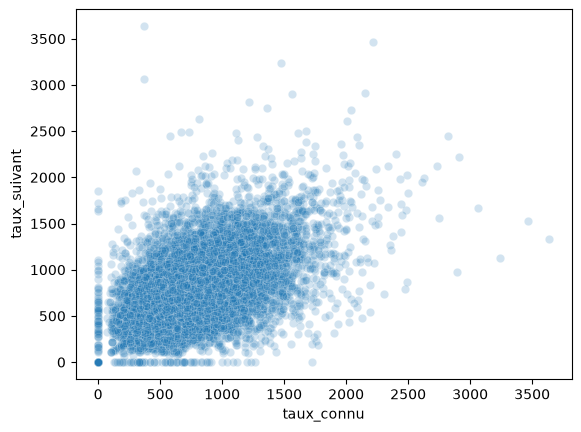

In [231]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(
    data=data,
    x="taux_connu",
    y="taux_suivant",
    alpha=0.2
)

plt.show()

Il y a une tendence positive, lors que taux_connu augmente, taux suivant augmente aussi. Mais il y a une ligne verticale x=0, maix y peut etre quand meme eleve, et y=0 mais taux connu peut etre elevé. 
Pour info, il y a des lignes 0, aucun valeur n'a pas ete remplace par 0 dans le fichier initiale

les points sont un paire semaine/departement

interessant: taux de la semaine actuelle 0 et la semaine suivante monte

In [232]:
#compter les observations 0
print("Taux connu = 0 :", (train["taux_connu"] == 0).sum())
print("Taux suivant = 0 :", (train["taux_suivant"] == 0).sum())

print("Taux connu = 0 et suivant > 0 :",
      ((train["taux_connu"] == 0) & (train["taux_suivant"] > 0)).sum())

print("Taux connu > 0 et suivant = 0 :",
      ((train["taux_connu"] > 0) & (train["taux_suivant"] == 0)).sum())

Taux connu = 0 : 45
Taux suivant = 0 : 43
Taux connu = 0 et suivant > 0 : 36
Taux connu > 0 et suivant = 0 : 34


In [ ]:
# Comparer correlation pearson vs spearman

#relation linaire
print("Pearson :", train["taux_connu"].corr(
    train["taux_suivant"], method="pearson"))

#co-evolution sans relation parfaitement linaire
print("Spearman :", train["taux_connu"].corr(
    train["taux_suivant"], method="spearman"))

Pearson : 0.5365815075544244
Spearman : 0.5127297090179572


On observere quand meme un relation positive lineaire et modere entre le taux_connu et taux_suivante

Mais pourquoi ElasticNet Ignore?
a) redondance avec autre variable
b) probelem de pretraitement

In [ ]:
#est-ce que la standardisation a fonctionne?
print(X_train_B["taux_connu"].describe())

count    9.888000e+03
mean    -2.558184e-16
std      1.000051e+00
min     -2.325765e+00
25%     -6.497083e-01
50%     -1.421468e-01
75%      4.823060e-01
max      8.929211e+00
Name: taux_connu, dtype: float64


In [236]:
from sklearn.linear_model import LinearRegression

modele_test = LinearRegression()

modele_test.fit(X_train_B[["taux_connu"]], y_train)

prediction_test = modele_test.predict(X_valid_B[["taux_connu"]])

afficher_scores("Régression taux connu seul", y_valid, prediction_test)

Régression taux connu seul
MAE  : 197.77
RMSE : 269.9
R²   : 0.303


La standardisation fonctionne : moyenne ≈ 0, écart-type ≈ 1.
taux_connu est informatif : utilisé seul, il explique environ 30 % de la variabilité des taux de 2023.
ElasticNet B l'ignore 

La variable taux_connu est correctement standardisée (moyenne ≈ 0, écart-type ≈ 1) et présente une corrélation positive modérée avec le taux de la semaine suivante (Pearson = 0,537 ; Spearman = 0,513).

Utilisée seule dans une régression linéaire, elle présente un pouvoir prédictif intéressant (R² = 0,303 sur la validation 2023), supérieur à celui de la baseline saisonnière (R² = 0,248).

Cependant, son ajout au modèle ElasticNet B n'améliore pas les performances par rapport au modèle A (R² = 0,375 dans les deux cas). ElasticNet lui attribue un coefficient nul, même lorsque la régularisation est diminuée.

Conclusion : le taux de la semaine précédente contient une information prédictive pertinente, mais n'apporte pas de gain supplémentaire dans le modèle ElasticNet actuel. Cela pourrait s'expliquer par une redondance avec d'autres variables explicatives, hypothèse qui reste à vérifier. Son intérêt peut etre réévalué avec des modèles non linéaires. 
